In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import OrderedDict
from google.colab import drive
drive.mount('/content/drive')

import torch
import torch.nn as nn
import torch.optim as optim

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.svm import SVR, SVC
from sklearn.metrics import (mean_squared_error, r2_score, accuracy_score, precision_score,
                              recall_score, f1_score, confusion_matrix)

Mounted at /content/drive


In [ ]:
def build_model(n_in, hidden, activation, n_out):
    layers = []
    d = n_in
    for i, h in enumerate(hidden, start=1):
        layers.append((f'hidden_linear{i}', nn.Linear(d, h)))
        layers.append((f'hidden_activation{i}', activation()))
        d = h
    layers.append(('output_linear', nn.Linear(d, n_out)))
    return nn.Sequential(OrderedDict(layers))


def training_loop(n_epochs, optimizer, model, loss_fn, X_train, X_val,
                  y_train, y_val, print_every=100):
    train_losses, val_losses = [], []
    for epoch in range(1, n_epochs + 1):
        t_p_train = model(X_train)
        loss_train = loss_fn(t_p_train, y_train)

        with torch.no_grad():
            t_p_val = model(X_val)
            loss_val = loss_fn(t_p_val, y_val)

        optimizer.zero_grad()
        loss_train.backward()
        optimizer.step()

        train_losses.append(loss_train.item())
        val_losses.append(loss_val.item())

        if print_every and (epoch == 1 or epoch % print_every == 0):
            print(f"Epoch {epoch}, Training loss {loss_train.item():.4f},"
                  f" Validation loss {loss_val.item():.4f}")

    return train_losses, val_losses

In [ ]:
housing_file_path = '/content/drive/My Drive/IntroToML/Housing.csv'
df = pd.read_csv(housing_file_path)

binary_cols = ['mainroad', 'guestroom', 'basement', 'hotwaterheating',
               'airconditioning', 'prefarea']
df[binary_cols] = df[binary_cols].apply(lambda col: col.map({'yes': 1, 'no': 0}))
df = pd.get_dummies(df, columns=['furnishingstatus'], drop_first=True, dtype=int)

housing_features = [c for c in df.columns if c != 'price']
print(len(housing_features), 'input features:', housing_features)

13 input features: ['area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furnishingstatus_semi-furnished', 'furnishingstatus_unfurnished']


In [ ]:
torch.manual_seed(42)
n_samples = len(df)
n_val = int(0.2 * n_samples)

shuffled_indices = torch.randperm(n_samples)
train_indices = shuffled_indices[:-n_val]
val_indices = shuffled_indices[-n_val:]

X = torch.tensor(df[housing_features].values, dtype=torch.float32)
y = torch.tensor(df['price'].values, dtype=torch.float32).unsqueeze(1)

X_train_h, X_val_h = X[train_indices], X[val_indices]
y_train_h, y_val_h = y[train_indices], y[val_indices]

x_mean, x_std = X_train_h.mean(dim=0), X_train_h.std(dim=0)
X_train_h = (X_train_h - x_mean) / x_std
X_val_h = (X_val_h - x_mean) / x_std

y_mean, y_std = y_train_h.mean(), y_train_h.std()
y_train_hs = (y_train_h - y_mean) / y_std
y_val_hs = (y_val_h - y_mean) / y_std

print('Training rows:', len(train_indices), ' Validation/test rows:', len(val_indices))

Training rows: 436  Validation/test rows: 109


In [ ]:
def run_housing_nn(hidden, activation, lr, weight_decay, n_epochs, seed=0, print_every=0):
    torch.manual_seed(seed)
    model = build_model(X_train_h.shape[1], hidden, activation, n_out=1)
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    train_losses, val_losses = training_loop(
        n_epochs=n_epochs, optimizer=optimizer, model=model, loss_fn=nn.MSELoss(),
        X_train=X_train_h, X_val=X_val_h, y_train=y_train_hs, y_val=y_val_hs,
        print_every=print_every)
    return model, train_losses, val_losses


def predict_price(model, X):
    with torch.no_grad():
        return (model(X).squeeze(1) * y_std + y_mean).numpy()


def reg_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {'MSE': mse, 'RMSE': mse ** 0.5, 'R2': r2_score(y_true, y_pred)}


y_test_prices = y_val_h.squeeze(1).numpy()

In [ ]:
rows = []
for hidden in [(8, 4), (16, 8), (32, 16)]:
    for activation in [nn.ReLU, nn.Tanh]:
        for lr in [1e-2, 1e-3]:
            model, tl, vl = run_housing_nn(hidden, activation, lr, weight_decay=1e-2, n_epochs=300)
            r2 = reg_metrics(y_test_prices, predict_price(model, X_val_h))['R2']
            rows.append({'hidden': hidden, 'activation': activation.__name__, 'lr': lr,
                         'train_loss': tl[-1], 'val_loss': vl[-1], 'test_R2': r2})

pd.DataFrame(rows).round(4)

,hidden,activation,lr,train_loss,val_loss,test_R2
0,"(8, 4)",ReLU,0.010,0.1747,0.3367,0.5623
1,"(8, 4)",ReLU,0.001,0.6337,0.4589,0.4039
2,"(8, 4)",Tanh,0.010,0.1520,0.3294,0.5714
3,"(8, 4)",Tanh,0.001,0.3027,0.2610,0.6606
4,"(16, 8)",ReLU,0.010,0.0955,0.3480,0.5488
5,"(16, 8)",ReLU,0.001,0.2357,0.2721,0.6461
6,"(16, 8)",Tanh,0.010,0.1163,0.3213,0.5852
7,"(16, 8)",Tanh,0.001,0.2988,0.2722,0.6461
8,"(32, 16)",ReLU,0.010,0.0603,0.3004,0.6217
9,"(32, 16)",ReLU,0.001,0.1871,0.2587,0.6637


In [ ]:
housing_model, train_losses_h, val_losses_h = run_housing_nn(
    hidden=(32, 16), activation=nn.Tanh, lr=1e-3, weight_decay=1e-2,
    n_epochs=300, seed=0, print_every=100)
print(housing_model)

Epoch 1, Training loss 0.8609, Validation loss 0.6427
Epoch 100, Training loss 0.3271, Validation loss 0.2647
Epoch 200, Training loss 0.2966, Validation loss 0.2575
Epoch 300, Training loss 0.2661, Validation loss 0.2494
Sequential(
  (hidden_linear1): Linear(in_features=13, out_features=32, bias=True)
  (hidden_activation1): Tanh()
  (hidden_linear2): Linear(in_features=32, out_features=16, bias=True)
  (hidden_activation2): Tanh()
  (output_linear): Linear(in_features=16, out_features=1, bias=True)
)


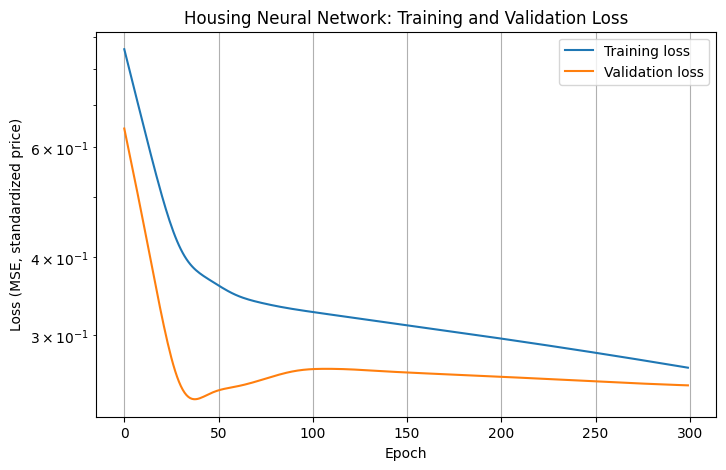

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(train_losses_h, label='Training loss')
plt.plot(val_losses_h, label='Validation loss')
plt.yscale('log')
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE, standardized price)')
plt.title('Housing Neural Network: Training and Validation Loss')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
nn_pred_h = predict_price(housing_model, X_val_h)
nn_metrics_h = reg_metrics(y_test_prices, nn_pred_h)
print('Neural network  MSE: %.4e   RMSE: %.0f   R2: %.4f' %
      (nn_metrics_h['MSE'], nn_metrics_h['RMSE'], nn_metrics_h['R2']))

Neural network  MSE: 9.1441e+11   RMSE: 956250   R2: 0.6759


In [ ]:
X_train_np, X_val_np = X_train_h.numpy(), X_val_h.numpy()

lin_reg = LinearRegression().fit(X_train_np, y_train_h.squeeze(1).numpy())
lin_pred_h = lin_reg.predict(X_val_np)

svr = SVR(kernel='linear', C=100).fit(X_train_np, y_train_hs.squeeze(1).numpy())
svr_pred_h = svr.predict(X_val_np) * y_std.item() + y_mean.item()

comparison_h = pd.DataFrame({
    'Linear Regression': reg_metrics(y_test_prices, lin_pred_h),
    'SVR (linear kernel)': reg_metrics(y_test_prices, svr_pred_h),
    'Neural Network': nn_metrics_h}).T

formatted = comparison_h.copy()
formatted['MSE'] = comparison_h['MSE'].map('{:.4e}'.format)
formatted['RMSE'] = comparison_h['RMSE'].map('{:,.0f}'.format)
formatted['R2'] = comparison_h['R2'].map('{:.4f}'.format)
print(formatted)

                            MSE     RMSE      R2
Linear Regression    9.2672e+11  962,663  0.6715
SVR (linear kernel)  9.7204e+11  985,921  0.6555
Neural Network       9.1441e+11  956,250  0.6759


In [ ]:
seed_r2 = []
for seed in range(5):
    m, _, _ = run_housing_nn((32, 16), nn.Tanh, 1e-3, 1e-2, 300, seed=seed)
    seed_r2.append(reg_metrics(y_test_prices, predict_price(m, X_val_h))['R2'])

print('Test R2 over 5 seeds:', np.round(seed_r2, 4))
print('Mean R2: %.4f   Std: %.4f' % (np.mean(seed_r2), np.std(seed_r2)))

Test R2 over 5 seeds: [0.6759 0.6576 0.6683 0.6465 0.6588]
Mean R2: 0.6614   Std: 0.0100


In [ ]:
cancer_file_path = '/content/drive/My Drive/IntroToML/Cancer.csv'
cancer_df = pd.read_csv(cancer_file_path)
cancer_df = cancer_df.drop(columns=['id'])
cancer_df = cancer_df.loc[:, ~cancer_df.columns.str.contains('^Unnamed')]
cancer_df['diagnosis'] = cancer_df['diagnosis'].map({'M': 1, 'B': 0})

X_cancer = cancer_df.drop(columns=['diagnosis']).values
y_cancer = cancer_df['diagnosis'].values

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_cancer, y_cancer, test_size=0.2, random_state=0, stratify=y_cancer)

sc = StandardScaler()
X_train_c = sc.fit_transform(X_train_c)
X_test_c = sc.transform(X_test_c)

print('Input features:', X_train_c.shape[1])
print('Training rows:', len(y_train_c), ' Test rows:', len(y_test_c))

Input features: 30
Training rows: 455  Test rows: 114


In [ ]:
X_train_ct = torch.tensor(X_train_c, dtype=torch.float32)
X_test_ct = torch.tensor(X_test_c, dtype=torch.float32)
y_train_ct = torch.tensor(y_train_c, dtype=torch.long)
y_test_ct = torch.tensor(y_test_c, dtype=torch.long)


def training_loop_clf(n_epochs, optimizer, model, loss_fn, X_train, X_val,
                      y_train, y_val, print_every=50):
    train_losses, val_losses, train_accs, val_accs = [], [], [], []
    for epoch in range(1, n_epochs + 1):
        t_p_train = model(X_train)
        loss_train = loss_fn(t_p_train, y_train)

        with torch.no_grad():
            t_p_val = model(X_val)
            loss_val = loss_fn(t_p_val, y_val)
            acc_train = (t_p_train.argmax(dim=1) == y_train).float().mean().item()
            acc_val = (t_p_val.argmax(dim=1) == y_val).float().mean().item()

        optimizer.zero_grad()
        loss_train.backward()
        optimizer.step()

        train_losses.append(loss_train.item())
        val_losses.append(loss_val.item())
        train_accs.append(acc_train)
        val_accs.append(acc_val)

        if print_every and (epoch == 1 or epoch % print_every == 0):
            print(f"Epoch {epoch}, Training loss {loss_train.item():.4f},"
                  f" Validation loss {loss_val.item():.4f},"
                  f" Training acc {acc_train:.4f}, Validation acc {acc_val:.4f}")

    return train_losses, val_losses, train_accs, val_accs


def run_cancer_nn(hidden, activation, lr, weight_decay, n_epochs, seed=0, print_every=0):
    torch.manual_seed(seed)
    model = build_model(X_train_ct.shape[1], hidden, activation, n_out=2)
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    history = training_loop_clf(
        n_epochs=n_epochs, optimizer=optimizer, model=model, loss_fn=nn.CrossEntropyLoss(),
        X_train=X_train_ct, X_val=X_test_ct, y_train=y_train_ct, y_val=y_test_ct,
        print_every=print_every)
    return (model,) + history


def class_metrics(y_true, y_pred):
    return {'accuracy': accuracy_score(y_true, y_pred),
            'precision': precision_score(y_true, y_pred),
            'recall': recall_score(y_true, y_pred),
            'f1': f1_score(y_true, y_pred)}


def predict_class(model, X):
    with torch.no_grad():
        return model(X).argmax(dim=1).numpy()


def plot_loss_and_accuracy(train_losses, val_losses, train_accs, val_accs, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    axes[0].plot(train_losses, label='Training loss')
    axes[0].plot(val_losses, label='Validation loss')
    axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss (cross-entropy)')
    axes[0].set_title(f'Loss over Epochs {title}'); axes[0].legend(); axes[0].grid(True)
    axes[1].plot(train_accs, label='Training accuracy')
    axes[1].plot(val_accs, label='Validation accuracy')
    axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy')
    axes[1].set_title(f'Accuracy over Epochs {title}'); axes[1].legend(); axes[1].grid(True)
    plt.tight_layout()
    plt.show()


def plot_confusion_matrix(cm, title):
    class_names = [0, 1]
    fig, ax = plt.subplots()
    tick_marks = np.arange(len(class_names))
    plt.xticks(tick_marks, class_names)
    plt.yticks(tick_marks, class_names)
    sns.heatmap(pd.DataFrame(cm), annot=True, cmap='YlGnBu', fmt='g')
    ax.xaxis.set_label_position('top')
    plt.tight_layout()
    plt.title(f'Confusion Matrix {title}', y=1.1)
    plt.ylabel('Actual label')
    plt.xlabel('Predicted label')
    plt.show()

In [ ]:
rows = []
for hidden in [(8, 4), (16, 8), (32, 16)]:
    for activation in [nn.ReLU, nn.Tanh]:
        for lr in [1e-2, 1e-3]:
            model, tl, vl, ta, va = run_cancer_nn(hidden, activation, lr, 0.0, 200)
            rows.append({'hidden': hidden, 'activation': activation.__name__, 'lr': lr,
                         'train_loss': tl[-1], 'val_loss': vl[-1],
                         'train_acc': ta[-1], 'val_acc': va[-1]})

pd.DataFrame(rows).round(4)

,hidden,activation,lr,train_loss,val_loss,train_acc,val_acc
0,"(8, 4)",ReLU,0.010,0.0347,0.2144,1.0000,0.9474
1,"(8, 4)",ReLU,0.001,0.3075,0.3626,0.9802,0.9737
2,"(8, 4)",Tanh,0.010,0.0263,0.1881,0.9956,0.9211
3,"(8, 4)",Tanh,0.001,0.1437,0.1864,0.9890,0.9386
4,"(16, 8)",ReLU,0.010,0.0004,0.2621,1.0000,0.9474
5,"(16, 8)",ReLU,0.001,0.0600,0.1158,0.9890,0.9561
6,"(16, 8)",Tanh,0.010,0.0168,0.1557,0.9956,0.9298
7,"(16, 8)",Tanh,0.001,0.0707,0.1115,0.9890,0.9737
8,"(32, 16)",ReLU,0.010,0.0004,0.2431,1.0000,0.9561
9,"(32, 16)",ReLU,0.001,0.0329,0.1142,0.9934,0.9386


In [ ]:
cancer_model, tl_c, vl_c, ta_c, va_c = run_cancer_nn(
    hidden=(32, 16), activation=nn.Tanh, lr=1e-3, weight_decay=0.0,
    n_epochs=200, seed=0, print_every=50)
print(cancer_model)

Epoch 1, Training loss 0.6887, Validation loss 0.6760, Training acc 0.6154, Validation acc 0.6228
Epoch 50, Training loss 0.1449, Validation loss 0.1792, Training acc 0.9604, Validation acc 0.9561
Epoch 100, Training loss 0.0715, Validation loss 0.1100, Training acc 0.9846, Validation acc 0.9474
Epoch 150, Training loss 0.0547, Validation loss 0.1033, Training acc 0.9890, Validation acc 0.9649
Epoch 200, Training loss 0.0471, Validation loss 0.1073, Training acc 0.9912, Validation acc 0.9649
Sequential(
  (hidden_linear1): Linear(in_features=30, out_features=32, bias=True)
  (hidden_activation1): Tanh()
  (hidden_linear2): Linear(in_features=32, out_features=16, bias=True)
  (hidden_activation2): Tanh()
  (output_linear): Linear(in_features=16, out_features=2, bias=True)
)


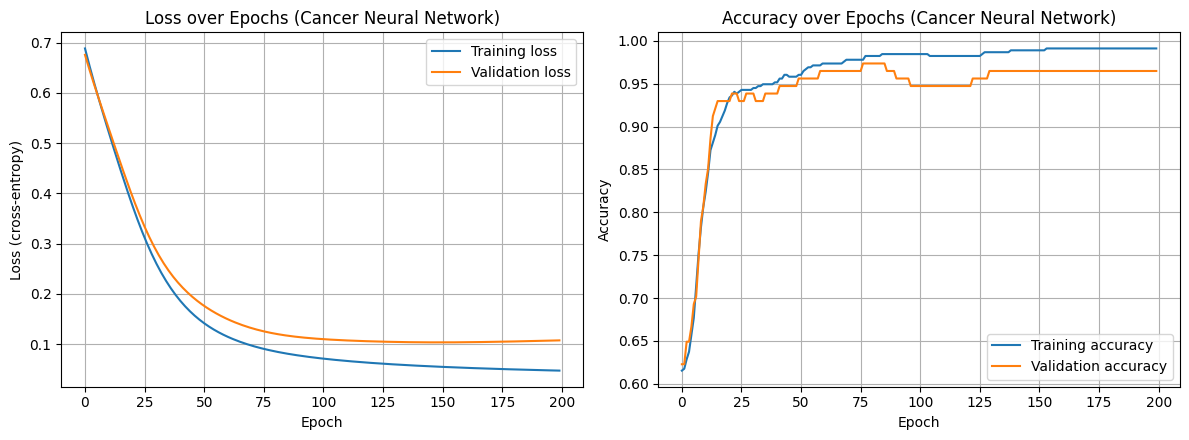

In [ ]:
plot_loss_and_accuracy(tl_c, vl_c, ta_c, va_c, '(Cancer Neural Network)')

Neural network - test set
  accuracy   0.9649
  precision  0.9524
  recall     0.9524
  f1         0.9524


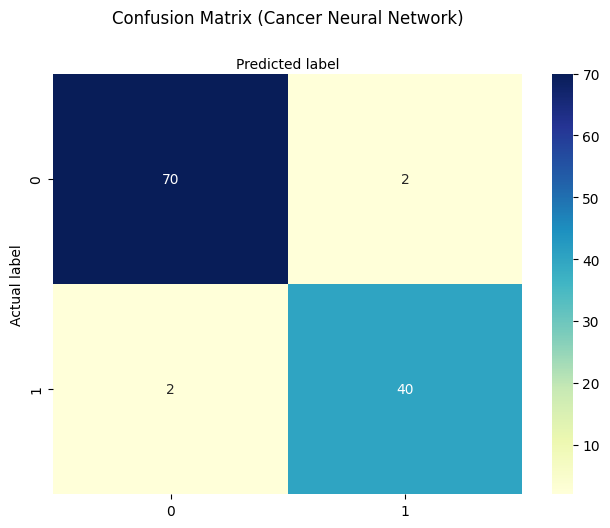

In [ ]:
nn_pred_c = predict_class(cancer_model, X_test_ct)
nn_metrics_c = class_metrics(y_test_c, nn_pred_c)
print('Neural network - test set')
for name, value in nn_metrics_c.items():
    print(f'  {name:<10} {value:.4f}')

plot_confusion_matrix(confusion_matrix(y_test_c, nn_pred_c), '(Cancer Neural Network)')

In [ ]:
log_reg = LogisticRegression().fit(X_train_c, y_train_c)
svm = SVC(kernel='rbf', class_weight='balanced').fit(X_train_c, y_train_c)

comparison_c = pd.DataFrame({
    'Logistic Regression': class_metrics(y_test_c, log_reg.predict(X_test_c)),
    'SVM (RBF kernel)': class_metrics(y_test_c, svm.predict(X_test_c)),
    'Neural Network': nn_metrics_c}).T
print(comparison_c.round(4))

                     accuracy  precision  recall      f1
Logistic Regression    0.9737     0.9756  0.9524  0.9639
SVM (RBF kernel)       0.9474     0.9091  0.9524  0.9302
Neural Network         0.9649     0.9524  0.9524  0.9524


In [ ]:
seed_results = []
for seed in range(5):
    m, *_ = run_cancer_nn((32, 16), nn.Tanh, 1e-3, 0.0, 200, seed=seed)
    seed_results.append(class_metrics(y_test_c, predict_class(m, X_test_ct)))

seed_df = pd.DataFrame(seed_results)
print(seed_df.round(4))
print()
print('Mean:'); print(seed_df.mean().round(4))
print('Std:');  print(seed_df.std(ddof=0).round(4))

   accuracy  precision  recall      f1
0    0.9649     0.9524  0.9524  0.9524
1    0.9649     0.9524  0.9524  0.9524
2    0.9474     0.9091  0.9524  0.9302
3    0.9649     0.9524  0.9524  0.9524
4    0.9649     0.9524  0.9524  0.9524

Mean:
accuracy     0.9614
precision    0.9437
recall       0.9524
f1           0.9480
dtype: float64
Std:
accuracy     0.0070
precision    0.0173
recall       0.0000
f1           0.0089
dtype: float64
